In [1]:
import pandas as pd
import numpy as np
from scipy.stats import zscore

In [2]:
data = {
    "Student": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"],
    "Marks": [50, 55, 60, 62, 65, 68, 70, 72, 75, 150]
}
df = pd.DataFrame(data)
print(df)

  Student  Marks
0       A     50
1       B     55
2       C     60
3       D     62
4       E     65
5       F     68
6       G     70
7       H     72
8       I     75
9       J    150


In [3]:
Q1 = df["Marks"].quantile(0.25)
print(Q1)
Q3 = df["Marks"].quantile(0.75)
print(Q3)

IQR = Q3 - Q1
print(IQR)

lower = Q1 - 1.5 * IQR
print(lower)
upper = Q3 + 1.5 * IQR
print(upper)

60.5
71.5
11.0
44.0
88.0


In [4]:
outliers = df[(df["Marks"] < lower) | (df["Marks"] > upper)]
print(outliers)

  Student  Marks
9       J    150


In [5]:
df["Marks_Treated"] = np.where(df["Marks"] < lower, lower, df["Marks"])
df["Marks_Treated"] = np.where(df["Marks_Treated"] > upper, upper, df["Marks_Treated"])

print(df)

  Student  Marks  Marks_Treated
0       A     50           50.0
1       B     55           55.0
2       C     60           60.0
3       D     62           62.0
4       E     65           65.0
5       F     68           68.0
6       G     70           70.0
7       H     72           72.0
8       I     75           75.0
9       J    150           88.0


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

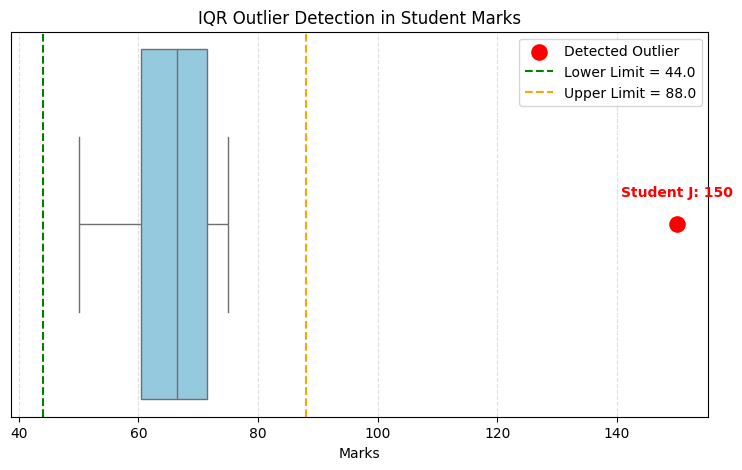

In [7]:
# Create the box plot
plt.figure(figsize=(9, 5))

sns.boxplot(x=df["Marks"], color="skyblue")

# Highlight the outliers detected by the IQR method
plt.scatter(
    outliers["Marks"],
    [0] * len(outliers),
    color="red",
    s=120,
    label="Detected Outlier",
    zorder=5
)

# Label each detected outlier
for _, row in outliers.iterrows():
    plt.annotate(
        f'Student {row["Student"]}: {row["Marks"]}',
        (row["Marks"], 0),
        xytext=(0, 20),
        textcoords="offset points",
        ha="center",
        color="red",
        fontweight="bold"
    )

# Display IQR limits
plt.axvline(
    lower, color="green", linestyle="--",
    label=f"Lower Limit = {lower}"
)
plt.axvline(
    upper, color="orange", linestyle="--",
    label=f"Upper Limit = {upper}"
)

plt.title("IQR Outlier Detection in Student Marks")
plt.xlabel("Marks")
plt.yticks([])
plt.legend()
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.show()

In [8]:
df_capped = df.copy()
df["Marks_Treated"] = df["Marks"].clip(lower, upper)

print("\nAfter Capping:")
print(df)


After Capping:
  Student  Marks  Marks_Treated
0       A     50             50
1       B     55             55
2       C     60             60
3       D     62             62
4       E     65             65
5       F     68             68
6       G     70             70
7       H     72             72
8       I     75             75
9       J    150             88


In [9]:
data={
    "students" : ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J",
            "K", "L", "M", "N", "O", "P", "Q", "R", "S", "T"],

"marks" : [50, 52, 54, 55, 56, 58, 60, 61, 62, 63,
         64, 65, 66, 68, 70, 71, 72, 73, 75, 200]
}
df = pd.DataFrame(data)
print(df)

   students  marks
0         A     50
1         B     52
2         C     54
3         D     55
4         E     56
5         F     58
6         G     60
7         H     61
8         I     62
9         J     63
10        K     64
11        L     65
12        M     66
13        N     68
14        O     70
15        P     71
16        Q     72
17        R     73
18        S     75
19        T    200


In [10]:
df["Z_Score"] = zscore(df["marks"])

print(df)

   students  marks   Z_Score
0         A     50 -0.643187
1         B     52 -0.578054
2         C     54 -0.512921
3         D     55 -0.480355
4         E     56 -0.447788
5         F     58 -0.382655
6         G     60 -0.317523
7         H     61 -0.284956
8         I     62 -0.252390
9         J     63 -0.219823
10        K     64 -0.187257
11        L     65 -0.154691
12        M     66 -0.122124
13        N     68 -0.056991
14        O     70  0.008142
15        P     71  0.040708
16        Q     72  0.073274
17        R     73  0.105841
18        S     75  0.170974
19        T    200  4.241777


In [11]:
outliers = df[abs(df["Z_Score"]) > 3]
print("\n outliers using z score:")
print(outliers)


 outliers using z score:
   students  marks   Z_Score
19        T    200  4.241777


In [12]:
mean = df["marks"].mean()
sd = df["marks"].std()

lower = mean - 3 * sd
upper = mean + 3 * sd
print("Mean:", mean)
print("Standard Deviation:", sd)
print("Lower Limit:", lower)
print("Upper Limit:", upper)
print(df)

Mean: 69.75
Standard Deviation: 31.504176832520745
Lower Limit: -24.76253049756224
Upper Limit: 164.26253049756224
   students  marks   Z_Score
0         A     50 -0.643187
1         B     52 -0.578054
2         C     54 -0.512921
3         D     55 -0.480355
4         E     56 -0.447788
5         F     58 -0.382655
6         G     60 -0.317523
7         H     61 -0.284956
8         I     62 -0.252390
9         J     63 -0.219823
10        K     64 -0.187257
11        L     65 -0.154691
12        M     66 -0.122124
13        N     68 -0.056991
14        O     70  0.008142
15        P     71  0.040708
16        Q     72  0.073274
17        R     73  0.105841
18        S     75  0.170974
19        T    200  4.241777


In [13]:
z = (df["marks"] - mean) / sd

df["marks_treated"] = df["marks"].clip(lower, upper)
print(df[["students", "marks", "marks_treated"]])

   students  marks  marks_treated
0         A     50       50.00000
1         B     52       52.00000
2         C     54       54.00000
3         D     55       55.00000
4         E     56       56.00000
5         F     58       58.00000
6         G     60       60.00000
7         H     61       61.00000
8         I     62       62.00000
9         J     63       63.00000
10        K     64       64.00000
11        L     65       65.00000
12        M     66       66.00000
13        N     68       68.00000
14        O     70       70.00000
15        P     71       71.00000
16        Q     72       72.00000
17        R     73       73.00000
18        S     75       75.00000
19        T    200      164.26253
